# ViT, MAE и DINOv2
Linear probe и partial fine-tuning на 20 классах Food-101. Сравниваем качество исходных признаков и результат адаптации двух последних блоков к классификации блюд.

*assisted with Codex*


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve()
if project_root.name == "seminar_02":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from seminar_02.runtime import load_config, seed_everything, environment_info
from seminar_02.data import create_dataloaders, dataset_table
from seminar_02.sanity import backbone_checks
from seminar_02.experiments import load_saved_experiment, run_experiment, results_table, compare_results, summarize_results
from seminar_02.evaluate import classification_reports, error_analysis
from seminar_02.features import comparison_features
from seminar_02.visualize import plot_samples, plot_learning_curves, plot_confusion_matrices
from seminar_02.visualize import plot_metric_comparison, plot_errors, compare_embeddings, plot_attention_examples

D:\.WORK_FOLDER\Projects\Edu\CV-Course\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
train_models = False # скипает трейн и использует готовые результаты (я графики дебажил)

config = load_config()
config["log_every"] = 5
backbones = ("supervised", "mae", "dinov2")
report_dir = Path(config["results_dir"]) / "presentation"
report_dir.mkdir(parents=True, exist_ok=True)

seed_everything(config["seed"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

display(pd.Series(environment_info(), name="Окружение").to_frame())
display(pd.Series({
    "Seed": config["seed"],
    "Classes": len(config["data"]["classes"]),
    "LP epochs": config["linear_probe"]["epochs"],
    "FT epochs": config["finetune"]["epochs"],
    "Unfrozen blocks": config["finetune"]["unfreeze_blocks"],
    "AMP": config["amp_dtype"] if config["amp"] else "off",
    "Microbatch": config["data"]["batch_size"],
    "Accumulation": config["finetune"]["accumulation_steps"],
    "Effective batch": config["data"]["batch_size"] * config["finetune"]["accumulation_steps"],
}, name="Параметры").to_frame())

,Окружение
python,3.14.8
torch,2.14.0+cu130
torchvision,0.29.0+cu130
timm,1.0.30
cuda,13.0
cuda_available,True
gpu,NVIDIA GeForce RTX 5060 Ti
vram,8123 MB


,Параметры
Seed,42
Classes,20
LP epochs,20
FT epochs,40
Unfrozen blocks,2
AMP,bfloat16
Microbatch,8
Accumulation,8
Effective batch,64


## Данные
По 700 train, 100 validation и 200 test на класс; всего 20 000 фотографий. В validation входят 50 изображений из официального train и 50 из официального test. Разбиение фиксируется до обучения и одинаково для всех моделей.

Фотографии приводятся к входу 224x224. Для fine-tuning используем случайный crop и horizontal flip; для validation и test – Resize(256) и центральный crop.

,train,val,test
class,,,
apple_pie,700,100,200
beef_carpaccio,700,100,200
bibimbap,700,100,200
caesar_salad,700,100,200
cheesecake,700,100,200
chicken_curry,700,100,200
chocolate_cake,700,100,200
club_sandwich,700,100,200
donuts,700,100,200


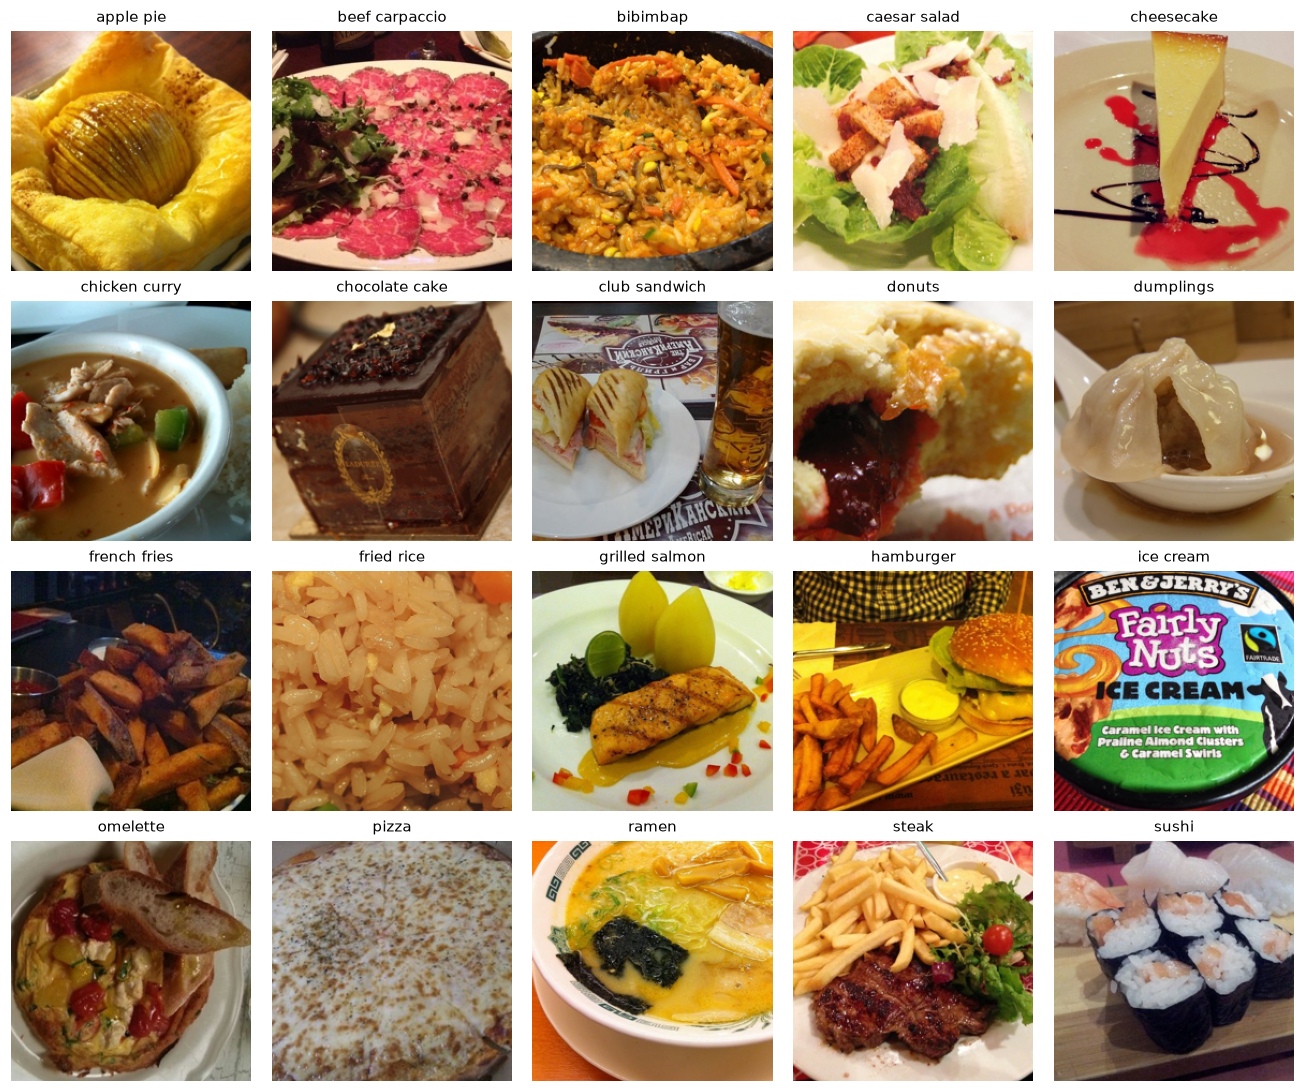

supervised: загружен supervised_linear_probe_20261012_142955_114079
mae: загружен mae_linear_probe_20261012_143153_809896
dinov2: загружен dinov2_linear_probe_20261012_143358_811092
supervised: загружен supervised_finetune_20261012_143408_430363
mae: загружен mae_finetune_20261012_153621_473015
dinov2: загружен dinov2_finetune_20261012_163713_404756


In [3]:
bundle = create_dataloaders(config)
display(dataset_table(bundle))

plot_samples(bundle.loaders["train"].dataset, bundle.class_names, count=len(bundle.class_names),
             one_per_class=True, path=report_dir / "samples.png")
plt.show()

if not train_models:
    probes = {
        name: load_saved_experiment(config, name, "linear_probe", bundle.manifest)
        for name in backbones
    }
    finetuned = {
        name: load_saved_experiment(config, name, "finetune", bundle.manifest,
                                    probe_checkpoint=probes[name]["checkpoint"])
        for name in backbones
    }


Проверка backbone и линейной головы на одном батче выполняется перед обучением. В режиме просмотра готовых результатов она пропускается.


In [ ]:
if train_models:
    display(backbone_checks(config, bundle).round(4))


## Linear probe
Encoder заморожен; обучается только $Wz+b$ поверх CLS-признака $z$. AdamW, 20 эпох, lr=1e-3, weight decay=1e-4. Признаки кешируются, голова обучается в FP32.

In [5]:
if train_models:
    probes = {
        name: run_experiment(config, name, "linear_probe")
        for name in backbones
    }


supervised: linear_probe
supervised: extracting train features (14000 images)
supervised: extracting val features (2000 images)
supervised: extracting test features (4000 images)
epoch=5 train_loss=0.1807 val_f1=0.9334
epoch=10 train_loss=0.1157 val_f1=0.9320
epoch=15 train_loss=0.0805 val_f1=0.9319
epoch=20 train_loss=0.0574 val_f1=0.9375
mae: linear_probe
mae: extracting train features (14000 images)
mae: extracting val features (2000 images)
mae: extracting test features (4000 images)
epoch=5 train_loss=1.9612 val_f1=0.5448
epoch=10 train_loss=1.5987 val_f1=0.6242
epoch=15 train_loss=1.4138 val_f1=0.6451
epoch=20 train_loss=1.2957 val_f1=0.6790
dinov2: linear_probe
dinov2: extracting train features (14000 images)
dinov2: extracting val features (2000 images)
dinov2: extracting test features (4000 images)
epoch=5 train_loss=0.0804 val_f1=0.9600
epoch=10 train_loss=0.0359 val_f1=0.9570
epoch=15 train_loss=0.0193 val_f1=0.9575
epoch=20 train_loss=0.0115 val_f1=0.9581


,mode,best_epoch,val_macro_f1,test_loss,test_accuracy,test_macro_f1,train_val_f1_gap
backbone,,,,,,,
supervised,linear_probe,8,0.938,0.1419,0.9568,0.9567,0.0246
mae,linear_probe,20,0.679,1.1876,0.6878,0.6859,-0.0215
dinov2,linear_probe,5,0.960,0.0763,0.9772,0.9772,0.0190


**supervised**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.9282,0.9050,0.9165,200
beef_carpaccio,0.9646,0.9550,0.9598,200
bibimbap,0.9847,0.9650,0.9747,200
caesar_salad,0.9659,0.9900,0.9778,200
cheesecake,0.9405,0.8700,0.9039,200
chicken_curry,0.9592,0.9400,0.9495,200
chocolate_cake,0.9009,0.9550,0.9272,200
club_sandwich,0.9754,0.9900,0.9826,200
donuts,0.9515,0.9800,0.9655,200


**mae**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.5000,0.4450,0.4709,200
beef_carpaccio,0.7268,0.7050,0.7157,200
bibimbap,0.8031,0.7750,0.7888,200
caesar_salad,0.7061,0.8050,0.7523,200
cheesecake,0.5714,0.5800,0.5757,200
chicken_curry,0.5767,0.6200,0.5976,200
chocolate_cake,0.6749,0.6850,0.6799,200
club_sandwich,0.7087,0.7300,0.7192,200
donuts,0.7118,0.8150,0.7599,200


**dinov2**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.9463,0.9700,0.9580,200
beef_carpaccio,0.9706,0.9900,0.9802,200
bibimbap,0.9704,0.9850,0.9777,200
caesar_salad,0.9850,0.9850,0.9850,200
cheesecake,0.9543,0.9400,0.9471,200
chicken_curry,0.9796,0.9600,0.9697,200
chocolate_cake,0.9602,0.9650,0.9626,200
club_sandwich,0.9756,1.0000,0.9877,200
donuts,1.0000,1.0000,1.0000,200


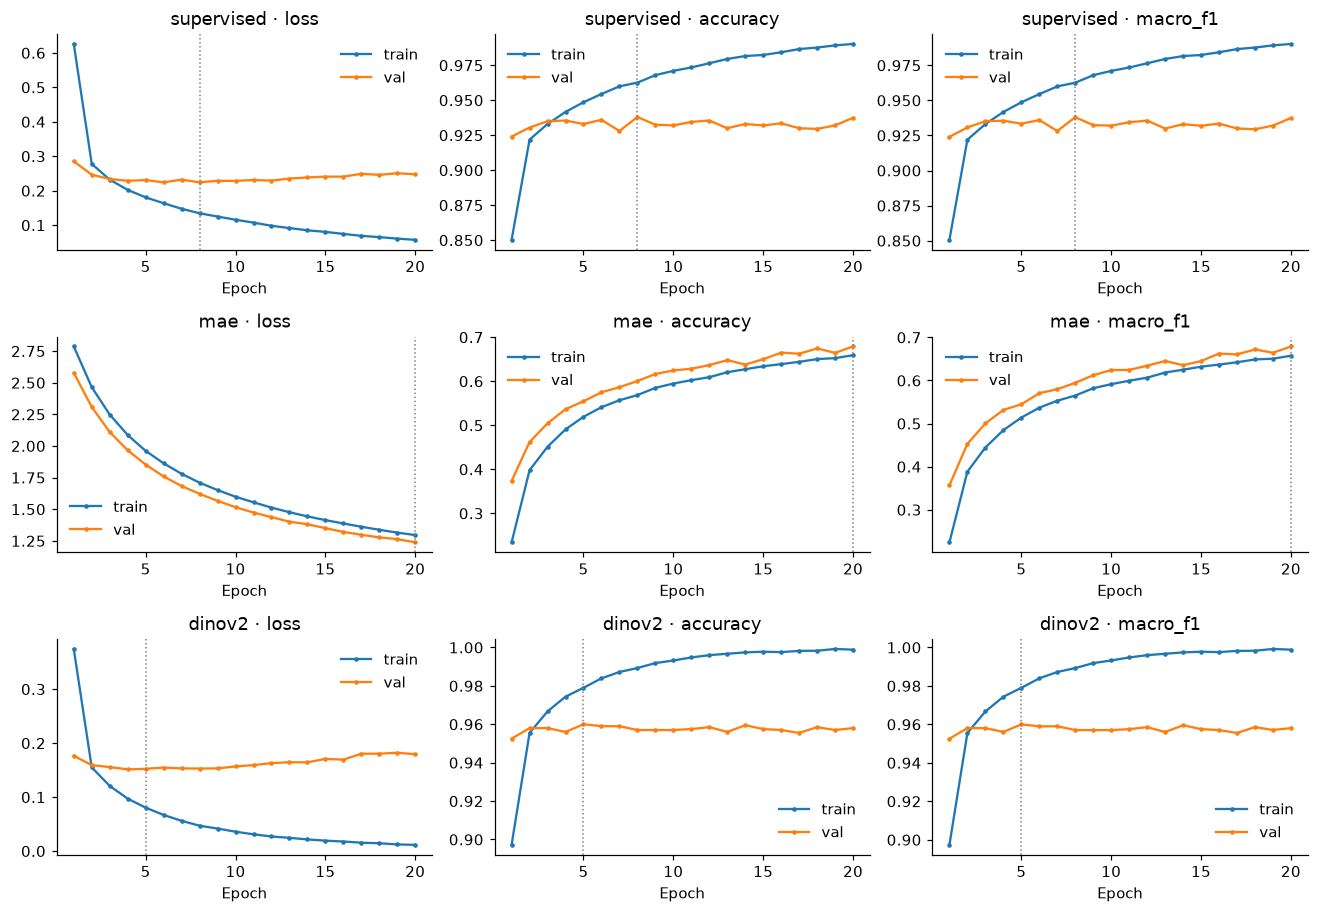

In [4]:
linear_metrics = results_table(probes)
linear_metrics.to_csv(report_dir / "linear_probe.csv")
display(linear_metrics.round(4))
reports = classification_reports(probes)
for name in backbones:
    display(Markdown(f"**{name}**"))
    display(reports.loc[name].round(4))

plot_learning_curves(probes, path=report_dir / "linear_probe_curves.png")
plt.show()

## Partial fine-tuning
Начинаем с лучшей linear head и размораживаем два последних transformer blocks и финальную LayerNorm. Верхний блок учится с lr=5e-5, предыдущий – с lr=3.25e-5, голова – с lr=5e-4. Обучение длится 40 эпох: 4 эпохи warmup, затем cosine decay.

На RTX 5060 Ti 8 GB используем AMP BF16 и microbatch 8 с накоплением 8 шагов: эффективный batch равен 64. По кривым сопоставим снижение train loss с изменением validation macro-F1. Пунктир отмечает выбранный checkpoint.

In [7]:
if train_models:
    finetuned = {
        name: run_experiment(config, name, "finetune", probe_checkpoint=probes[name]["checkpoint"])
        for name in backbones
    }


supervised: finetune


d:\.WORK_FOLDER\Projects\Edu\CV-Course\.venv\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\transformers\cuda\attention_backward.cu:912.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


epoch=5 train_loss=0.0888 val_f1=0.9360
epoch=10 train_loss=0.0201 val_f1=0.9411
epoch=15 train_loss=0.0076 val_f1=0.9451
epoch=20 train_loss=0.0046 val_f1=0.9456
epoch=25 train_loss=0.0041 val_f1=0.9455
epoch=30 train_loss=0.0021 val_f1=0.9465
epoch=35 train_loss=0.0021 val_f1=0.9461
epoch=40 train_loss=0.0017 val_f1=0.9466
mae: finetune
epoch=5 train_loss=0.5023 val_f1=0.8539
epoch=10 train_loss=0.1960 val_f1=0.8741
epoch=15 train_loss=0.0706 val_f1=0.8750
epoch=20 train_loss=0.0278 val_f1=0.8710
epoch=25 train_loss=0.0134 val_f1=0.8837
epoch=30 train_loss=0.0069 val_f1=0.8839
epoch=35 train_loss=0.0035 val_f1=0.8830
epoch=40 train_loss=0.0041 val_f1=0.8866
dinov2: finetune
epoch=5 train_loss=0.0711 val_f1=0.9508
epoch=10 train_loss=0.0217 val_f1=0.9600
epoch=15 train_loss=0.0102 val_f1=0.9685
epoch=20 train_loss=0.0033 val_f1=0.9615
epoch=25 train_loss=0.0005 val_f1=0.9665
epoch=30 train_loss=0.0010 val_f1=0.9690
epoch=35 train_loss=0.0002 val_f1=0.9690
epoch=40 train_loss=0.0001 va

,mode,best_epoch,val_macro_f1,test_loss,test_accuracy,test_macro_f1,train_val_f1_gap
backbone,,,,,,,
supervised,finetune,21,0.9485,0.1454,0.9645,0.9645,0.0506
mae,finetune,39,0.8871,0.4961,0.9192,0.9191,0.1117
dinov2,finetune,38,0.9700,0.1621,0.9845,0.9845,0.0299


**supervised**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.9200,0.9200,0.9200,200
beef_carpaccio,0.9557,0.9700,0.9628,200
bibimbap,0.9700,0.9700,0.9700,200
caesar_salad,0.9754,0.9900,0.9826,200
cheesecake,0.9433,0.9150,0.9289,200
chicken_curry,0.9596,0.9500,0.9548,200
chocolate_cake,0.9317,0.9550,0.9432,200
club_sandwich,0.9802,0.9900,0.9851,200
donuts,0.9655,0.9800,0.9727,200


**mae**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.8846,0.8050,0.8429,200
beef_carpaccio,0.9461,0.9650,0.9554,200
bibimbap,0.9406,0.9500,0.9453,200
caesar_salad,0.9461,0.9650,0.9554,200
cheesecake,0.8923,0.8700,0.8810,200
chicken_curry,0.8303,0.9050,0.8660,200
chocolate_cake,0.9137,0.9000,0.9068,200
club_sandwich,0.9310,0.9450,0.9380,200
donuts,0.9275,0.9600,0.9435,200


**dinov2**

,precision,recall,f1-score,support
class,,,,
apple_pie,0.9655,0.9800,0.9727,200
beef_carpaccio,0.9950,0.9900,0.9925,200
bibimbap,0.9900,0.9900,0.9900,200
caesar_salad,0.9950,1.0000,0.9975,200
cheesecake,0.9785,0.9100,0.9430,200
chicken_curry,0.9800,0.9800,0.9800,200
chocolate_cake,0.9515,0.9800,0.9655,200
club_sandwich,0.9755,0.9950,0.9851,200
donuts,0.9950,1.0000,0.9975,200


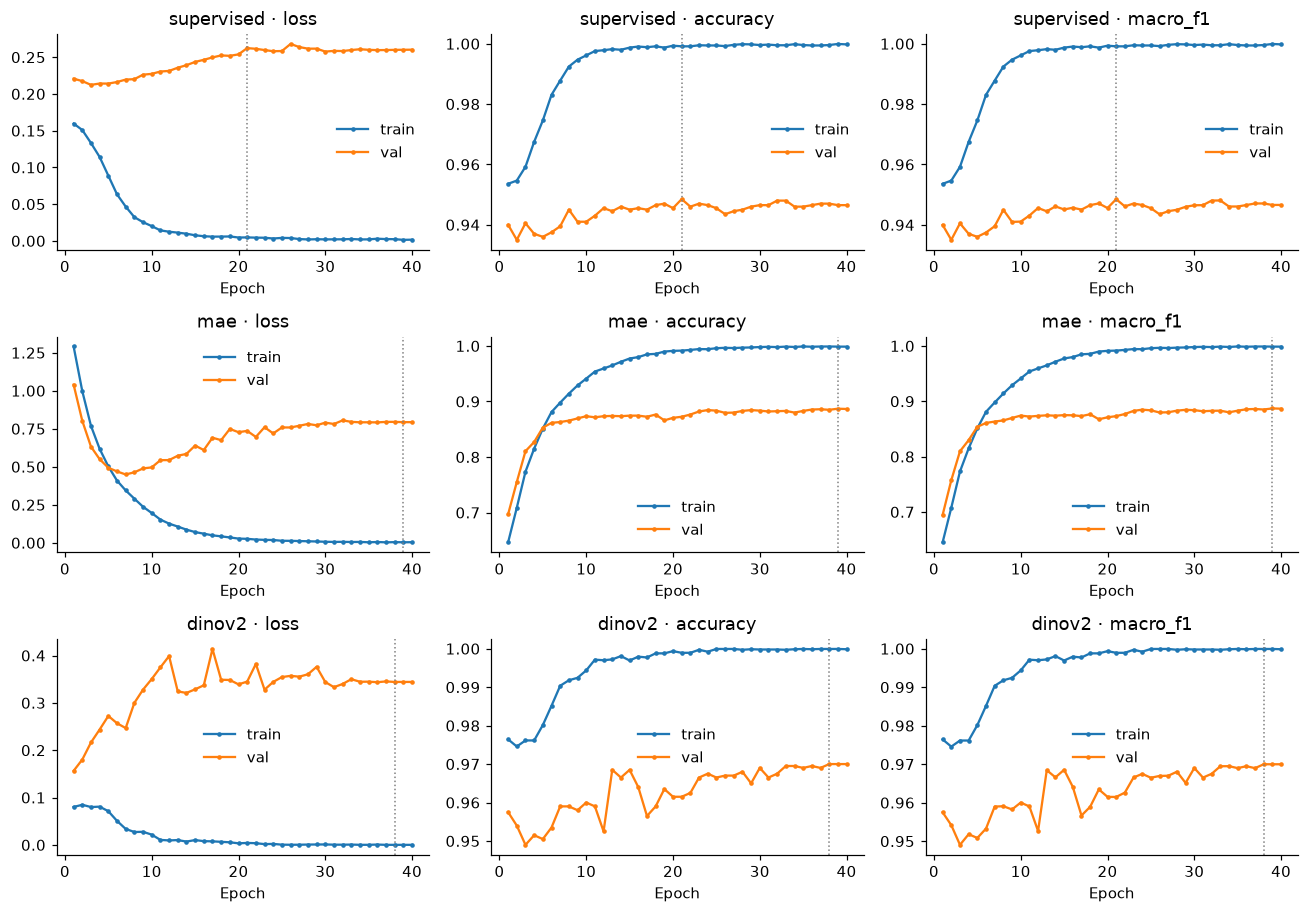

In [5]:
finetune_metrics = results_table(finetuned)
finetune_metrics.to_csv(report_dir / "finetune.csv")
display(finetune_metrics.round(4))
reports = classification_reports(finetuned)
for name in backbones:
    display(Markdown(f"**{name}**"))
    display(reports.loc[name].round(4))

plot_learning_curves(finetuned, path=report_dir / "finetune_curves.png")
plt.show()

## Сравнение
Таблица показывает test accuracy и macro-F1 до и после fine-tuning, а также разницу в процентных пунктах. Сравним исходное качество признаков и выигрыш от адаптации каждого backbone.

В confusion matrices строки – истинные блюда, столбцы – предсказания. Для каждого backbone linear probe и fine-tuning расположены рядом: так видны пары классов, которые модель стала различать лучше.

,LP accuracy,FT accuracy,"delta accuracy, pp",LP macro_f1,FT macro_f1,"delta macro_f1, pp"
backbone,,,,,,
supervised,0.9568,0.9645,0.775,0.9567,0.9645,0.7787
mae,0.6878,0.9192,23.150,0.6859,0.9191,23.3208
dinov2,0.9772,0.9845,0.725,0.9772,0.9845,0.7231


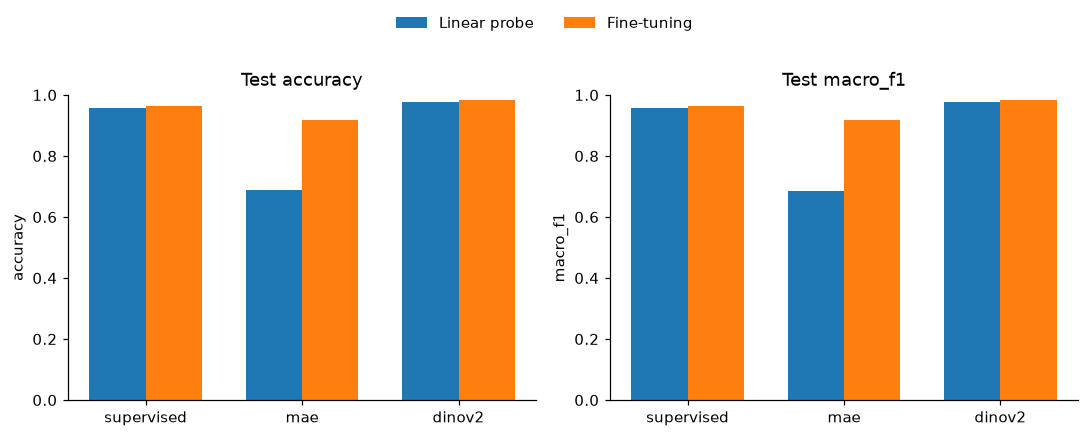

In [2]:
comparison = compare_results(probes, finetuned, path=report_dir / "comparison.csv")
display(comparison.round(4))

plot_metric_comparison(comparison, path=report_dir / "comparison.png")
plt.show()

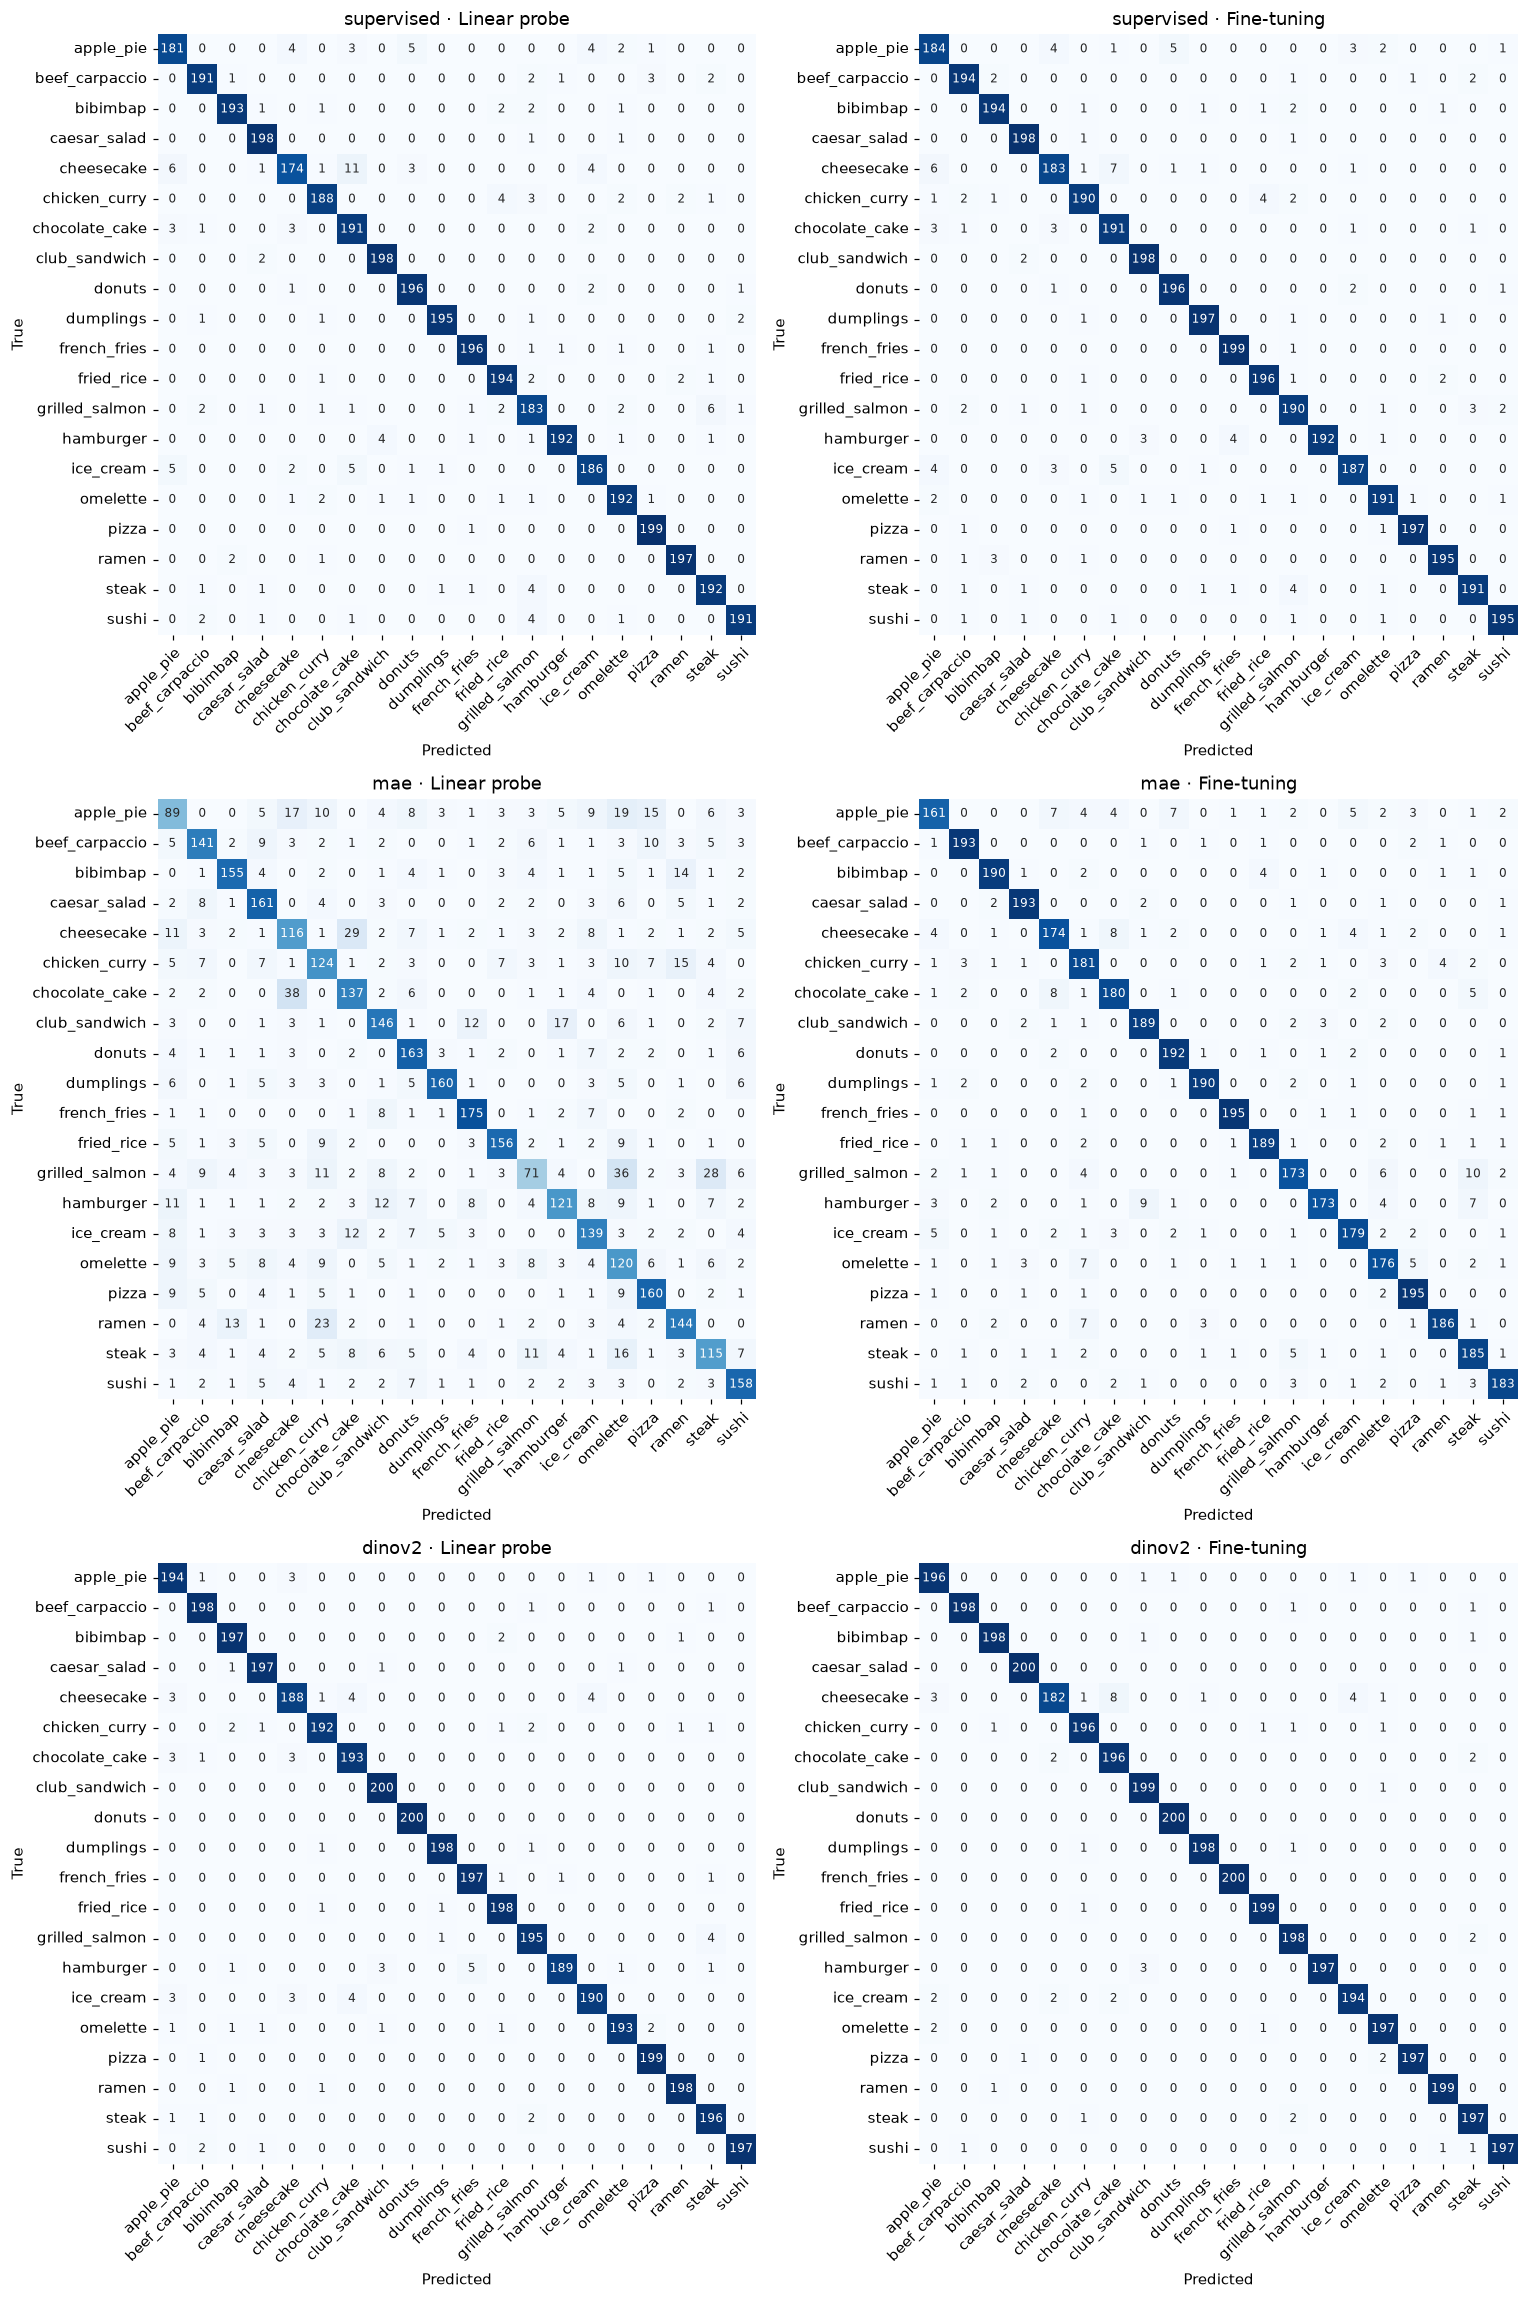

In [3]:
plot_confusion_matrices(probes, finetuned, path=report_dir / "confusion_matrices.png")
plt.show()

## Ошибки классификации
Разберём модель с лучшим validation macro-F1. Таблица отсортирована по числу пропущенных изображений класса (FN), при равенстве — по числу ложных срабатываний (FP).

Для трёх первых классов покажем самые уверенные FP и FN. Сопоставим ингредиенты, форму блюда, посуду и фон. Уверенность в заголовке — максимальная softmax-вероятность модели.


dinov2 / finetune


,class,false_positives,false_negatives,support
0,cheesecake,4,18,200
1,ice_cream,5,6,200
2,chocolate_cake,10,4,200
3,apple_pie,7,4,200
4,chicken_curry,4,4,200
5,steak,7,3,200
6,omelette,5,3,200
7,pizza,1,3,200
8,hamburger,0,3,200
9,sushi,0,3,200


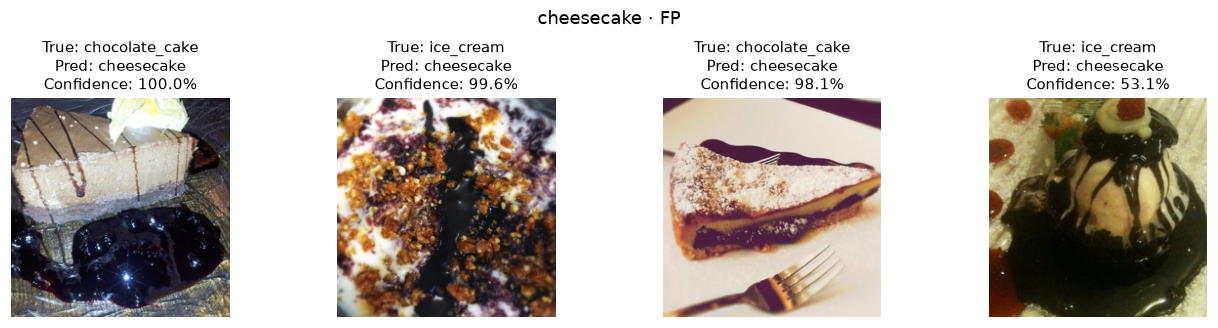

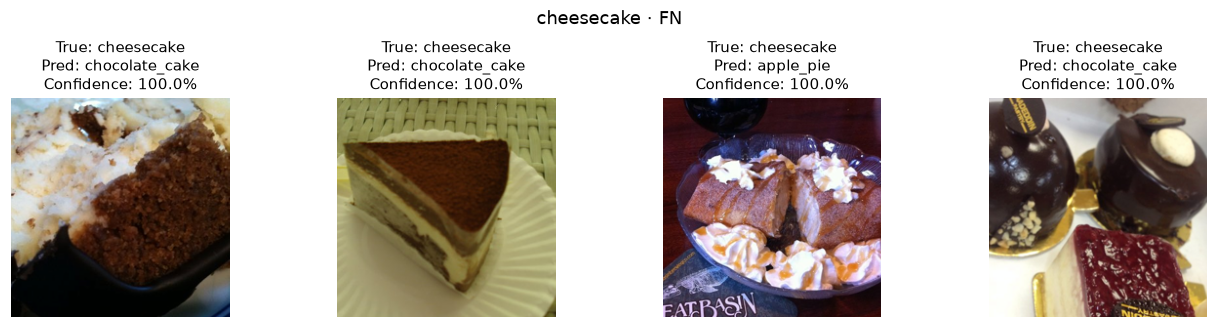

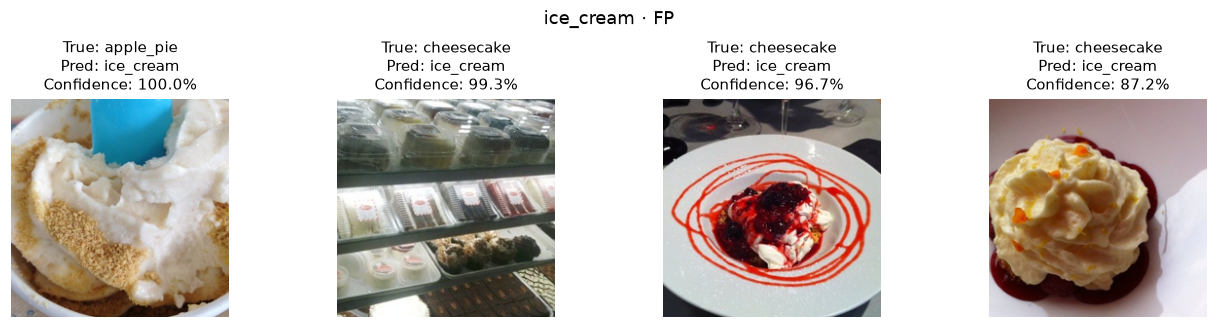

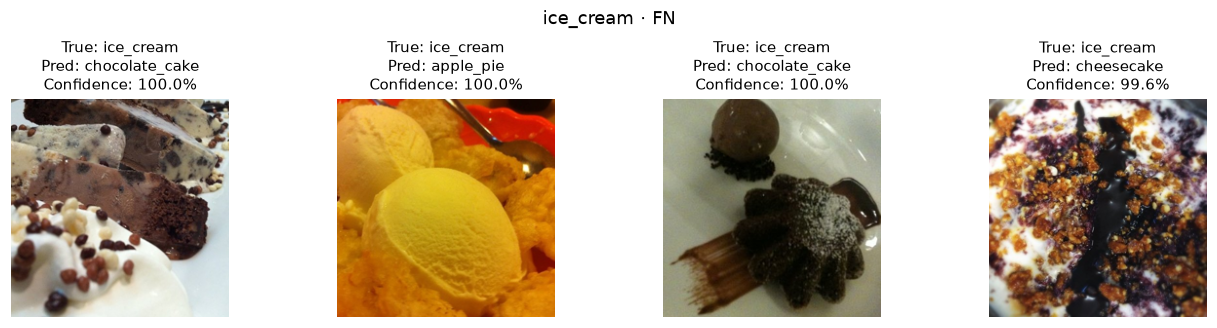

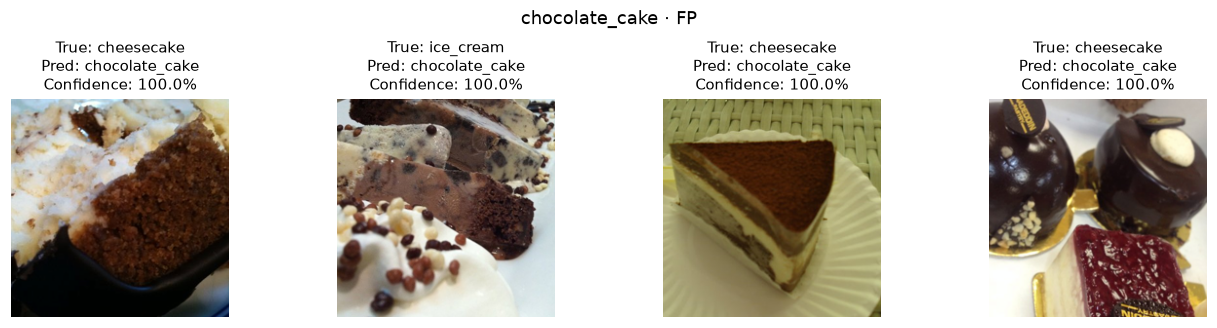

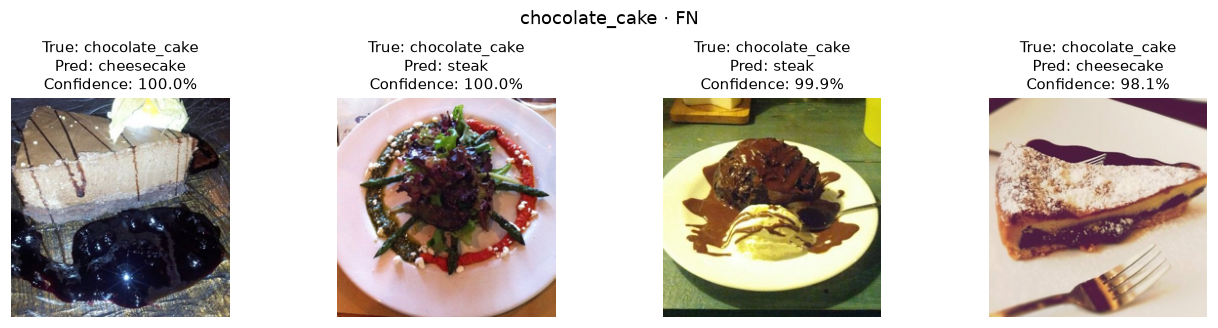

In [8]:
selected = max([*probes.values(), *finetuned.values()], key=lambda result: result["best_val_macro_f1"])
print(f"{selected['backbone']} / {selected['mode']}")

errors = error_analysis(selected["test"], bundle.class_names)
errors = errors.sort_values(["false_negatives", "false_positives"], ascending=False).reset_index(drop=True)
errors.to_csv(report_dir / "errors.csv", index=False)
display(errors)

error_classes = errors.loc[errors["false_negatives"] + errors["false_positives"] > 0, "class"].head(3)
for class_name in error_classes:
    for kind in ("fp", "fn"):
        plot_errors(bundle.loaders["test"].dataset, selected["test"], bundle.class_names,
                    class_index=bundle.class_names.index(class_name), kind=kind, count=4,
                    path=report_dir / f"{class_name}_{kind}.png")
        plt.show()


## Пространство признаков
Для трёх backbone берём одни и те же 1 000 test-изображений и CLS-признаки исходных pretrained моделей из кеша. После L2-нормализации и PCA строим t-SNE и UMAP.

Сравним компактность групп и смешение похожих блюд внутри каждой панели. Сопоставим пересекающиеся группы с ошибками linear probe в confusion matrix. Метрики классификации выше рассчитаны по всем 4 000 test-изображениям.

In [12]:
embeddings, labels = comparison_features(config, bundle)

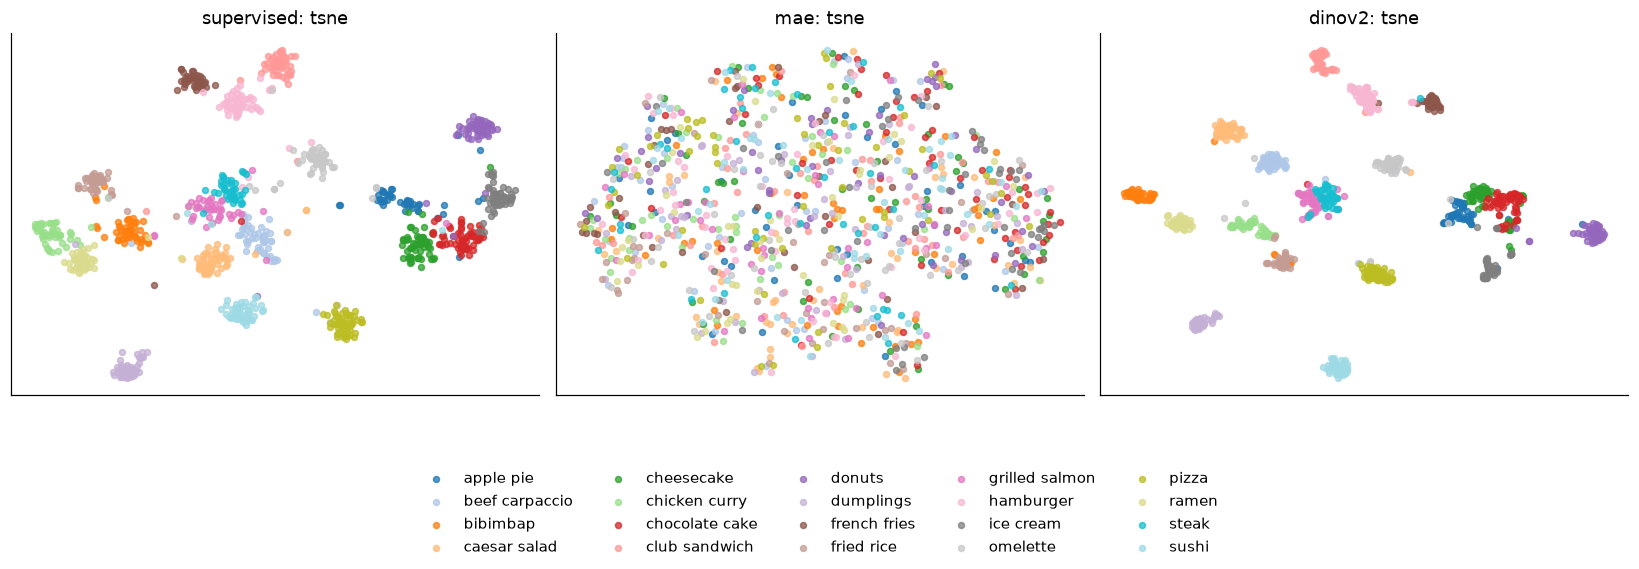

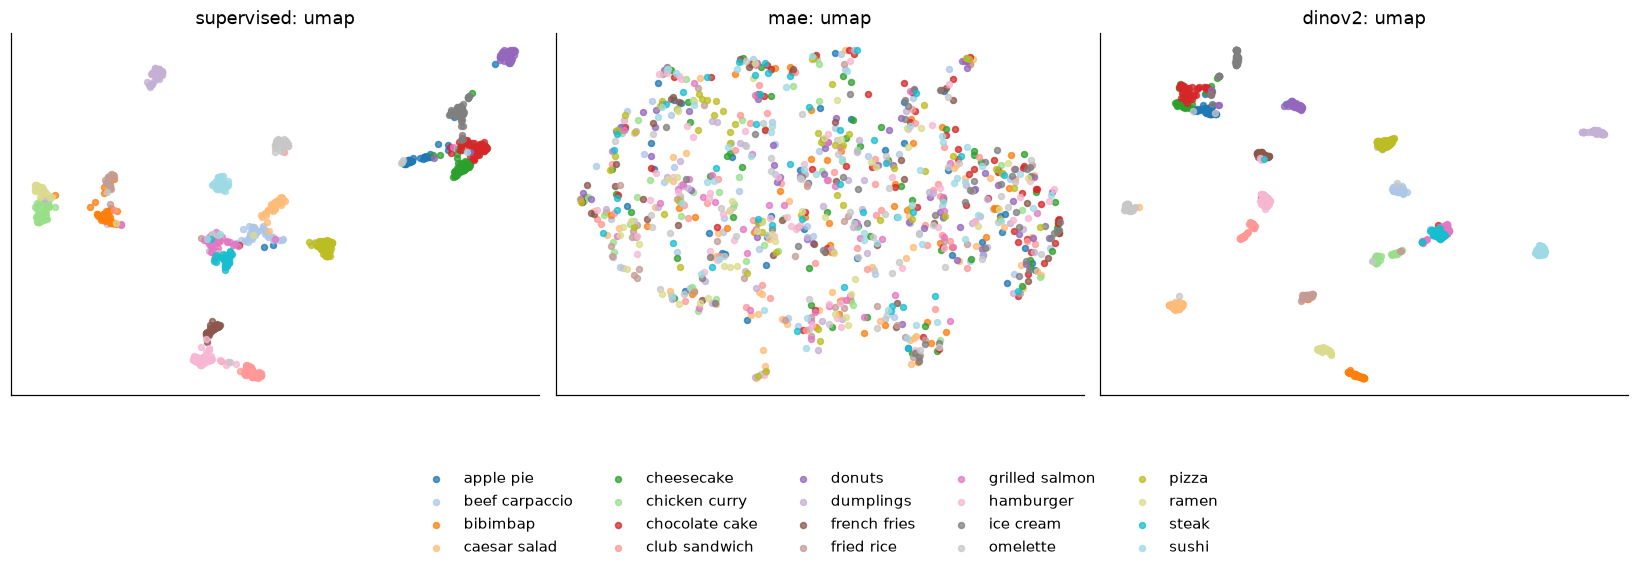

In [13]:
for method in ("tsne", "umap"):
    compare_embeddings(embeddings, labels, bundle.class_names, method=method,
                       seed=config["seed"], max_samples=1000, path=report_dir / f"{method}.png")
    plt.show()

## Внимание DINOv2
Attention rollout объединяет матрицы внимания всех блоков с учётом residual-связей. Используем исходную pretrained DINOv2, до fine-tuning. На двух фотографиях посмотрим, куда направлено внимание CLS: на само блюдо, отдельные ингредиенты, посуду или окружающий фон.

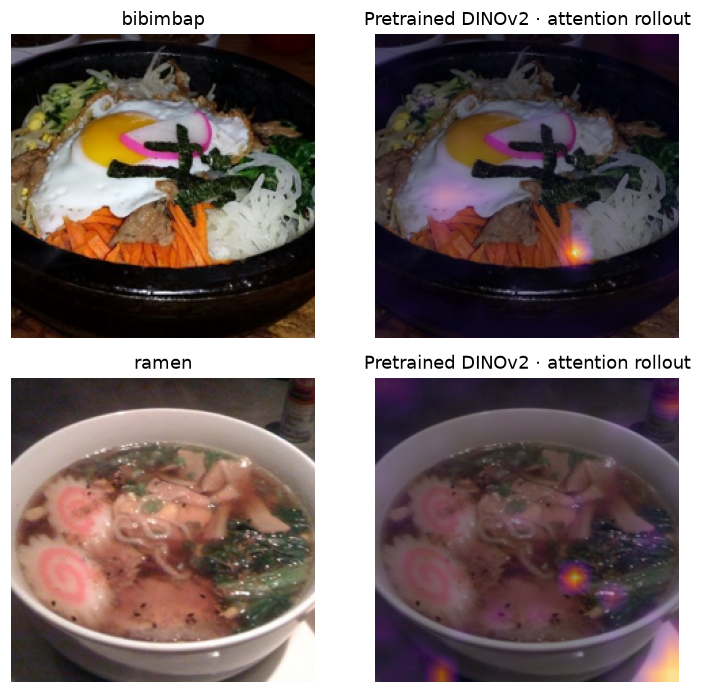

In [9]:
plot_attention_examples(config, bundle.loaders["test"].dataset, bundle.class_names,
                        indices=(0, 1), path=report_dir / "attention.png")
plt.show()

## Результат
Сведём результаты: какая модель выбрана по validation, сколько дал fine-tuning каждому backbone и какие блюда чаще всего путает выбранный классификатор.

In [10]:
summary = summarize_results(probes, finetuned)
(report_dir / "summary.md").write_text(summary, encoding="utf-8")
display(Markdown(summary))

По validation macro-F1 выбрана dinov2 / finetune: 0.970. На test: accuracy 0.985, macro-F1 0.984.

supervised: изменение test macro-F1 после fine-tuning +0.78 п.п.

mae: изменение test macro-F1 после fine-tuning +23.32 п.п.

dinov2: изменение test macro-F1 после fine-tuning +0.72 п.п.

Наибольший прирост macro-F1 у mae: +23.32 п.п.

Самая частая ошибка выбранной модели: cheesecake → chocolate_cake, 8 изображений.